DD-SIMCA INTERACTIVO
Flujo: SNV + Savitzky-Golay + modelo PCA por clase



Ingresa la carpeta donde están los CSV [.]:  C:\Users\YERALD\



CSV encontrados:
1. APRONAX.csv
2. NAP_FARMI.csv
3. NAP_QZ.csv
4. historial_completo_con_productos.csv



Escribe los números de los CSV separados por coma. Ejemplo: 1,2,3 1,2,3



Asigna una etiqueta/clase para cada archivo.


Etiqueta para APRONAX.csv [APRONAX]:  APRONAX
Etiqueta para NAP_FARMI.csv [NAP_FARMI]:  FARMA_INDUSTRIA
Etiqueta para NAP_QZ.csv [NAP_QZ]:  QUIMICA_SUIZA

Ventana Savitzky-Golay [17]:  17
Orden del polinomio Savitzky-Golay [2]:  2
Orden de derivada Savitzky-Golay [1]:  

Número de componentes PCA por clase para DD-SIMCA [3]:  3
Nivel de confianza DD-SIMCA: escribe 95 o 99 [95]:  99

¿Deseas exportar resultados CSV? (s/n) [s]:  N


[OK] APRONAX.csv: 34 muestras, clase = APRONAX
[OK] NAP_FARMI.csv: 52 muestras, clase = FARMA_INDUSTRIA
[OK] NAP_QZ.csv: 50 muestras, clase = QUIMICA_SUIZA

Columnas de metadatos omitidas:
['Batch Number', 'Registration Date']

Matriz espectral cruda: (136, 228)
[ADVERTENCIA] Longitudes de onda no perfectamente equiespaciadas. Se usará delta promedio.

Preprocesamiento aplicado:
- SNV muestra por muestra
- Savitzky-Golay: ventana=17, polinomio=2, derivada=1, delta=3.515419

MODELO DD-SIMCA CLASE: APRONAX
Muestras de calibración: 34
Componentes usadas: 3
Límite T²: 14.318869
Límite Q: 0.00001708
PC1: 52.0689% | acumulada: 52.0689%
PC2: 34.4248% | acumulada: 86.4938%
PC3: 7.5341% | acumulada: 94.0279%


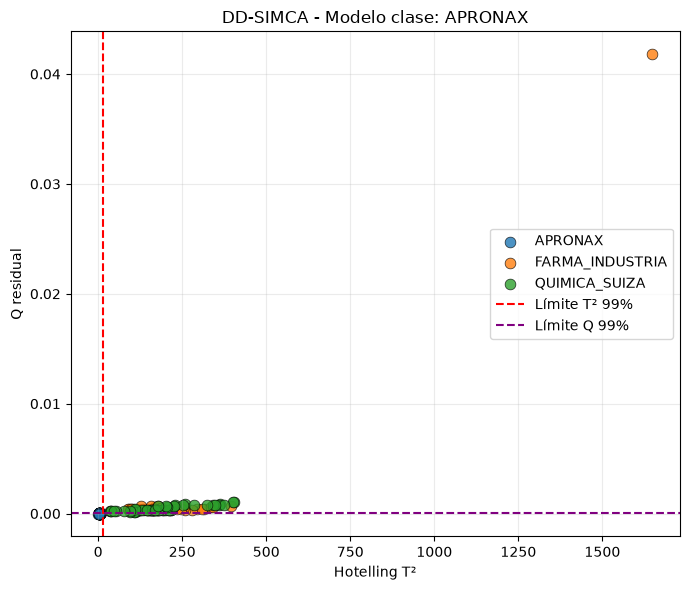


MODELO DD-SIMCA CLASE: FARMA_INDUSTRIA
Muestras de calibración: 52
Componentes usadas: 3
Límite T²: 13.140664
Límite Q: 0.00009540
PC1: 74.0234% | acumulada: 74.0234%
PC2: 22.5491% | acumulada: 96.5725%
PC3: 2.1015% | acumulada: 98.6740%


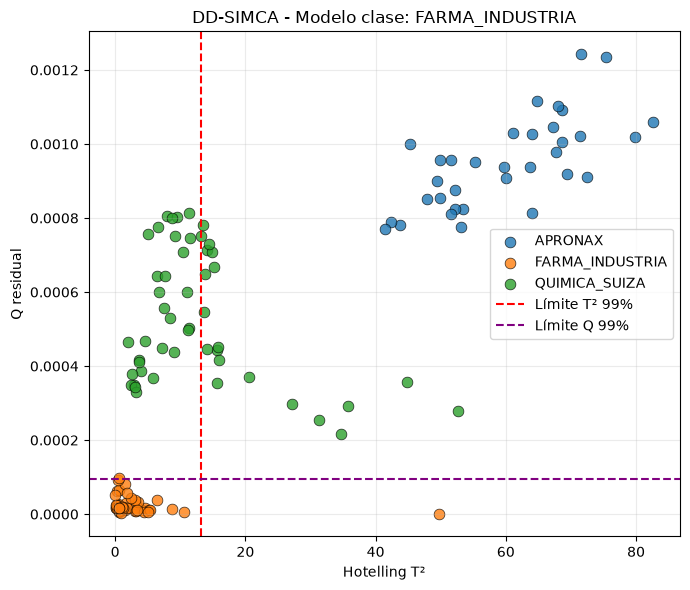


MODELO DD-SIMCA CLASE: QUIMICA_SUIZA
Muestras de calibración: 50
Componentes usadas: 3
Límite T²: 13.223434
Límite Q: 0.00003745
PC1: 94.9321% | acumulada: 94.9321%
PC2: 4.2312% | acumulada: 99.1633%
PC3: 0.4193% | acumulada: 99.5826%


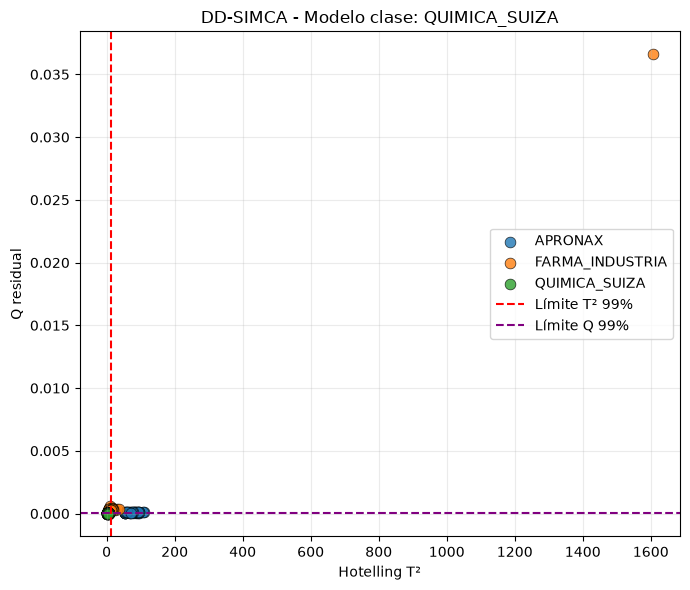


Matriz de aceptación DD-SIMCA:


Modelo_clase,Indice,Clase_real,APRONAX,FARMA_INDUSTRIA,QUIMICA_SUIZA
0,0,APRONAX,True,False,False
1,1,APRONAX,True,False,False
2,2,APRONAX,True,False,False
3,3,APRONAX,True,False,False
4,4,APRONAX,True,False,False
...,...,...,...,...,...
131,131,QUIMICA_SUIZA,False,False,False
132,132,QUIMICA_SUIZA,False,False,True
133,133,QUIMICA_SUIZA,False,False,True
134,134,QUIMICA_SUIZA,False,False,True



Resumen final:


Modelo_clase,Indice,Clase_real,APRONAX,FARMA_INDUSTRIA,QUIMICA_SUIZA,N_modelos_aceptan,Clasificacion_DD_SIMCA,Correcta
0,0,APRONAX,True,False,False,1,APRONAX,True
1,1,APRONAX,True,False,False,1,APRONAX,True
2,2,APRONAX,True,False,False,1,APRONAX,True
3,3,APRONAX,True,False,False,1,APRONAX,True
4,4,APRONAX,True,False,False,1,APRONAX,True
...,...,...,...,...,...,...,...,...
131,131,QUIMICA_SUIZA,False,False,False,0,Rechazada por todas,False
132,132,QUIMICA_SUIZA,False,False,True,1,QUIMICA_SUIZA,True
133,133,QUIMICA_SUIZA,False,False,True,1,QUIMICA_SUIZA,True
134,134,QUIMICA_SUIZA,False,False,True,1,QUIMICA_SUIZA,True



RESUMEN DD-SIMCA
Exactitud aparente: 97.06%
Muestras rechazadas por todas: 4
Muestras ambiguas: 0


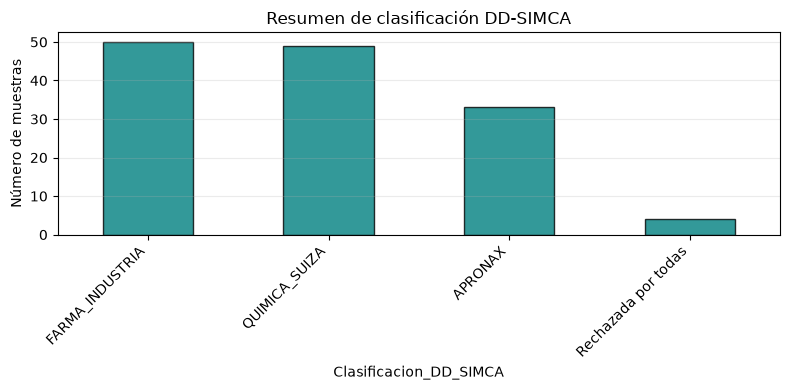

In [1]:
# ===========================================================================
# DD-SIMCA INTERACTIVO PARA ESPECTROS NIR
# Flujo: CSV -> SNV -> Savitzky-Golay -> DD-SIMCA por clase
# ===========================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import savgol_filter
from scipy.stats import f

plt.style.use("default")


# ===========================================================================
# FUNCIONES DE ENTRADA
# ===========================================================================

def pedir_texto(mensaje, default=None):
    if default is None:
        return input(mensaje).strip()
    txt = input(f"{mensaje} [{default}]: ").strip()
    return default if txt == "" else txt


def pedir_entero(mensaje, default=None, minimo=None):
    while True:
        txt = pedir_texto(mensaje, default)
        try:
            valor = int(txt)
            if minimo is not None and valor < minimo:
                print(f"Debe ser >= {minimo}")
                continue
            return valor
        except ValueError:
            print("Ingresa un número entero válido.")


def pedir_si_no(mensaje, default="s"):
    while True:
        txt = pedir_texto(f"{mensaje} (s/n)", default).lower()
        if txt in ["s", "si", "sí", "y", "yes"]:
            return True
        if txt in ["n", "no"]:
            return False
        print("Responde con s o n.")


def pedir_confianza():
    while True:
        txt = pedir_texto("Nivel de confianza DD-SIMCA: escribe 95 o 99", "95")
        if txt in ["95", "0.95"]:
            return 0.95
        if txt in ["99", "0.99"]:
            return 0.99
        print("Solo se permite 95 o 99.")


# ===========================================================================
# PREPROCESAMIENTO
# ===========================================================================

def listar_csv(carpeta):
    archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(".csv")]
    archivos.sort()
    return archivos


def aplicar_snv(X, ddof=0):
    media = X.mean(axis=1, keepdims=True)
    std = X.std(axis=1, ddof=ddof, keepdims=True)

    if np.any(std == 0):
        raise ValueError("Hay espectros con desviación estándar cero. No se puede aplicar SNV.")

    return (X - media) / std


def aplicar_savgol(X, longitudes_onda, window_length, polyorder, deriv):
    if window_length % 2 == 0:
        raise ValueError("La ventana Savitzky-Golay debe ser impar.")

    if window_length <= polyorder:
        raise ValueError("La ventana debe ser mayor que el orden del polinomio.")

    diffs = np.diff(longitudes_onda)

    if not np.allclose(diffs, diffs[0]):
        print("[ADVERTENCIA] Longitudes de onda no perfectamente equiespaciadas. Se usará delta promedio.")

    delta = np.mean(diffs)

    X_sg = savgol_filter(
        X,
        window_length=window_length,
        polyorder=polyorder,
        deriv=deriv,
        delta=delta,
        axis=1,
        mode="interp"
    )

    return X_sg, delta


# ===========================================================================
# DD-SIMCA
# ===========================================================================

def ajustar_modelo_ddsimca(X_clase, n_components, alpha=0.95):
    n, p = X_clase.shape
    a = min(n_components, n - 1, p)

    if a < 1:
        raise ValueError("No hay suficientes muestras para ajustar PCA de clase.")

    media = X_clase.mean(axis=0)
    Xc = X_clase - media

    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)

    loadings = Vt[:a, :]
    scores = Xc @ loadings.T
    eigenvalues = (S[:a] ** 2) / (n - 1)

    X_hat = scores @ loadings
    residual = Xc - X_hat

    T2_cal = np.sum((scores ** 2) / eigenvalues, axis=1)
    Q_cal = np.sum(residual ** 2, axis=1)

    if n > a:
        T2_lim_f = a * (n - 1) / (n - a) * f.ppf(alpha, a, n - a)
    else:
        T2_lim_f = np.quantile(T2_cal, alpha)

    # Límite empírico para Q residual. Es estable y transparente para uso exploratorio.
    Q_lim = np.quantile(Q_cal, alpha)

    var_ratio = (S[:a] ** 2) / np.sum(S ** 2) * 100
    var_acum = np.cumsum(var_ratio)

    return {
        "media": media,
        "loadings": loadings,
        "eigenvalues": eigenvalues,
        "T2_lim": T2_lim_f,
        "Q_lim": Q_lim,
        "T2_cal": T2_cal,
        "Q_cal": Q_cal,
        "var_ratio": var_ratio,
        "var_acum": var_acum,
        "n_components": a
    }


def predecir_ddsimca(X, modelo):
    Xc = X - modelo["media"]
    loadings = modelo["loadings"]
    eigenvalues = modelo["eigenvalues"]

    scores = Xc @ loadings.T
    X_hat = scores @ loadings
    residual = Xc - X_hat

    T2 = np.sum((scores ** 2) / eigenvalues, axis=1)
    Q = np.sum(residual ** 2, axis=1)

    aceptado = (T2 <= modelo["T2_lim"]) & (Q <= modelo["Q_lim"])

    return T2, Q, aceptado, scores


def graficar_ddsimca_clase(nombre_clase, modelo, T2, Q, y_labels, aceptado, alpha):
    confianza = int(alpha * 100)

    plt.figure(figsize=(7, 6))

    for clase in np.unique(y_labels):
        idx = y_labels == clase
        plt.scatter(
            T2[idx],
            Q[idx],
            label=clase,
            s=60,
            edgecolors="black",
            linewidths=0.5,
            alpha=0.8
        )

    plt.axvline(modelo["T2_lim"], color="red", linestyle="--", label=f"Límite T² {confianza}%")
    plt.axhline(modelo["Q_lim"], color="purple", linestyle="--", label=f"Límite Q {confianza}%")

    plt.xlabel("Hotelling T²")
    plt.ylabel("Q residual")
    plt.title(f"DD-SIMCA - Modelo clase: {nombre_clase}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


# ===========================================================================
# 1. CONFIGURACIÓN INTERACTIVA
# ===========================================================================

print("=" * 75)
print("DD-SIMCA INTERACTIVO")
print("Flujo: SNV + Savitzky-Golay + modelo PCA por clase")
print("=" * 75)

carpeta = pedir_texto("\nIngresa la carpeta donde están los CSV", ".")
carpeta = os.path.abspath(carpeta)

if not os.path.isdir(carpeta):
    raise FileNotFoundError(f"No existe la carpeta: {carpeta}")

csv_disponibles = listar_csv(carpeta)

print("\nCSV encontrados:")
for i, archivo in enumerate(csv_disponibles, start=1):
    print(f"{i}. {archivo}")

seleccion_txt = pedir_texto("\nEscribe los números de los CSV separados por coma. Ejemplo: 1,2,3")
indices_csv = [int(x.strip()) - 1 for x in seleccion_txt.split(",")]

archivos_seleccionados = [csv_disponibles[i] for i in indices_csv]

etiquetas_clase = {}

print("\nAsigna una etiqueta/clase para cada archivo.")
for archivo in archivos_seleccionados:
    etiqueta_default = os.path.splitext(archivo)[0]
    etiqueta = pedir_texto(f"Etiqueta para {archivo}", etiqueta_default)
    etiquetas_clase[archivo] = etiqueta

sg_window = pedir_entero("\nVentana Savitzky-Golay", default=17, minimo=3)
sg_polyorder = pedir_entero("Orden del polinomio Savitzky-Golay", default=2, minimo=1)
sg_deriv = pedir_entero("Orden de derivada Savitzky-Golay", default=1, minimo=0)

n_components = pedir_entero("\nNúmero de componentes PCA por clase para DD-SIMCA", default=3, minimo=1)
alpha = pedir_confianza()

exportar = pedir_si_no("\n¿Deseas exportar resultados CSV?", default="s")


# ===========================================================================
# 2. CARGA DE DATOS
# ===========================================================================

dfs = []
y_labels = []

for archivo in archivos_seleccionados:
    ruta = os.path.join(carpeta, archivo)
    df = pd.read_csv(ruta)
    clase = etiquetas_clase[archivo]

    dfs.append(df)
    y_labels.extend([clase] * len(df))

    print(f"[OK] {archivo}: {df.shape[0]} muestras, clase = {clase}")

df_global = pd.concat(dfs, ignore_index=True)
y_labels = np.array(y_labels)

columnas_convertidas = pd.to_numeric(df_global.columns, errors="coerce")
columnas_espectrales = df_global.columns[columnas_convertidas.notna()]
columnas_metadata = df_global.columns[columnas_convertidas.isna()]

longitudes_onda = columnas_convertidas[columnas_convertidas.notna()].astype(float).values
X_raw = df_global[columnas_espectrales].astype(float).values

orden = np.argsort(longitudes_onda)
longitudes_onda = longitudes_onda[orden]
X_raw = X_raw[:, orden]

print("\nColumnas de metadatos omitidas:")
print(list(columnas_metadata))

print(f"\nMatriz espectral cruda: {X_raw.shape}")

if np.isnan(X_raw).any():
    raise ValueError("La matriz contiene NaN.")

if np.isinf(X_raw).any():
    raise ValueError("La matriz contiene infinitos.")


# ===========================================================================
# 3. PREPROCESAMIENTO
# ===========================================================================

X_snv = aplicar_snv(X_raw, ddof=0)

X_proc, delta_sg = aplicar_savgol(
    X_snv,
    longitudes_onda,
    window_length=sg_window,
    polyorder=sg_polyorder,
    deriv=sg_deriv
)

print("\nPreprocesamiento aplicado:")
print("- SNV muestra por muestra")
print(f"- Savitzky-Golay: ventana={sg_window}, polinomio={sg_polyorder}, derivada={sg_deriv}, delta={delta_sg:.6f}")


# ===========================================================================
# 4. AJUSTE DD-SIMCA POR CLASE
# ===========================================================================

clases = np.unique(y_labels)
modelos = {}
resultados = []

for clase_modelo in clases:
    idx_clase = y_labels == clase_modelo
    X_clase = X_proc[idx_clase]

    modelo = ajustar_modelo_ddsimca(
        X_clase,
        n_components=n_components,
        alpha=alpha
    )

    modelos[clase_modelo] = modelo

    T2, Q, aceptado, scores_modelo = predecir_ddsimca(X_proc, modelo)

    print("\n" + "=" * 70)
    print(f"MODELO DD-SIMCA CLASE: {clase_modelo}")
    print("=" * 70)
    print(f"Muestras de calibración: {X_clase.shape[0]}")
    print(f"Componentes usadas: {modelo['n_components']}")
    print(f"Límite T²: {modelo['T2_lim']:.6f}")
    print(f"Límite Q: {modelo['Q_lim']:.8f}")

    for i, v in enumerate(modelo["var_ratio"], start=1):
        print(f"PC{i}: {v:.4f}% | acumulada: {modelo['var_acum'][i-1]:.4f}%")

    graficar_ddsimca_clase(
        clase_modelo,
        modelo,
        T2,
        Q,
        y_labels,
        aceptado,
        alpha
    )

    for i in range(X_proc.shape[0]):
        resultados.append({
            "Indice": i,
            "Clase_real": y_labels[i],
            "Modelo_clase": clase_modelo,
            "T2": T2[i],
            "Q_residual": Q[i],
            "T2_lim": modelo["T2_lim"],
            "Q_lim": modelo["Q_lim"],
            "Aceptado": aceptado[i]
        })


df_resultados = pd.DataFrame(resultados)


# ===========================================================================
# 5. MATRIZ DE ACEPTACIÓN
# ===========================================================================

df_aceptacion = df_resultados.pivot_table(
    index=["Indice", "Clase_real"],
    columns="Modelo_clase",
    values="Aceptado",
    aggfunc="first"
).reset_index()

print("\nMatriz de aceptación DD-SIMCA:")
display(df_aceptacion)

columnas_modelos = [c for c in df_aceptacion.columns if c not in ["Indice", "Clase_real"]]

df_aceptacion["N_modelos_aceptan"] = df_aceptacion[columnas_modelos].sum(axis=1)

def clasificacion_final(fila):
    aceptadas = [c for c in columnas_modelos if fila[c] == True]
    if len(aceptadas) == 0:
        return "Rechazada por todas"
    if len(aceptadas) == 1:
        return aceptadas[0]
    return "Ambigua: " + ", ".join(aceptadas)

df_aceptacion["Clasificacion_DD_SIMCA"] = df_aceptacion.apply(clasificacion_final, axis=1)
df_aceptacion["Correcta"] = df_aceptacion["Clase_real"] == df_aceptacion["Clasificacion_DD_SIMCA"]

print("\nResumen final:")
display(df_aceptacion)

accuracy = df_aceptacion["Correcta"].mean() * 100
rechazadas = (df_aceptacion["Clasificacion_DD_SIMCA"] == "Rechazada por todas").sum()
ambiguas = df_aceptacion["Clasificacion_DD_SIMCA"].str.startswith("Ambigua").sum()

print("\n" + "=" * 70)
print("RESUMEN DD-SIMCA")
print("=" * 70)
print(f"Exactitud aparente: {accuracy:.2f}%")
print(f"Muestras rechazadas por todas: {rechazadas}")
print(f"Muestras ambiguas: {ambiguas}")


# ===========================================================================
# 6. GRÁFICO RESUMEN DE ACEPTACIONES
# ===========================================================================

conteo = df_aceptacion["Clasificacion_DD_SIMCA"].value_counts()

plt.figure(figsize=(8, 4))
conteo.plot(kind="bar", color="teal", alpha=0.8, edgecolor="black")
plt.ylabel("Número de muestras")
plt.title("Resumen de clasificación DD-SIMCA")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# ===========================================================================
# 7. EXPORTACIÓN
# ===========================================================================

if exportar:
    carpeta_salida = os.path.join(carpeta, "resultados_ddsimca")
    os.makedirs(carpeta_salida, exist_ok=True)

    df_resultados.to_csv(os.path.join(carpeta_salida, "ddsimca_distancias_por_modelo.csv"), index=False)
    df_aceptacion.to_csv(os.path.join(carpeta_salida, "ddsimca_matriz_aceptacion.csv"), index=False)

    df_preprocesado = pd.DataFrame(X_proc, columns=[str(w) for w in longitudes_onda])
    df_preprocesado.insert(0, "Clase", y_labels)
    df_preprocesado.insert(0, "Indice", np.arange(len(y_labels)))
    df_preprocesado.to_csv(os.path.join(carpeta_salida, "matriz_preprocesada_snv_sg.csv"), index=False)

    print("\n[OK] Resultados exportados en:")
    print(carpeta_salida)